# 6 · Phase 5 checks: the last 11 °C, coarse-model fronts, a local Shmin and the static geotherm

**KAI-GeoEnergy · KAI Reservoir Lab · Utah FORGE, Milford, Utah (USA)**

Notebook 4 left four open questions. This notebook answers them.

1. **Static geotherm.** Is the temperature model (notebook 1, GDR 1205) hot at the wells? This is one candidate for part of the +11 °C bottom-hole misfit.
2. **Local thermal non-equilibrium (LTNE).** Water in a few fast fractures can stay colder than the rock blocks between them. Does that explain the +11 °C? What block size would it need? Is that size plausible against the fracture spacing in the data? What does it do to the 30-year forecast?
3. **A local Shmin.** The August 2024 test ran above the GDR 1222 Shmin. What do the 16B mini-frac tests say, and which rates are feasible against them?
4. **Coarse-model fronts.** Can a coarse model give the early breakthrough, with a correction, as well as the 30-year heat?

**New data** (DOE Geothermal Data Repository, CC BY 4.0; `data/` holds only derived values, rebuilt by `rebuild_data.py`):
* **16B mini-frac tests**, June–July 2023 (GDR 1570, Battelle with Baker Hughes): seven straddle-packer tests at 5,202–5,980 ft. We use the interval pressure and rate of each test. The interpretation report is GDR 1596; we quote two of its numbers.
* **16B pressure-temperature gauge**, 26 March – 20 April 2024 (GDR 1608, DOI [10.15121/2368548](https://doi.org/10.15121/2368548)): one gauge on the fibre at 7,056.67 ft MD.
* **16A(78)-32 temperature log**, 16 August 2021, about 216 days after the rig left (GDR 1421 workbook, from the cement-bond-log run). It reaches 3,349 m MD, inside the 16A open interval.

*Credit: Utah FORGE, U.S. Department of Energy, via the Geothermal Data Repository (OpenEI), CC BY 4.0.*

**Labels.** Every model number is **simulated** by the KAI Reservoir Lab engine (`results/kai_engine_phase5.json`). Data-derived numbers are recomputed here with the MIT helpers in `forge_tools.py`; the notebook stops if the engine disagrees.

In [1]:
import json, pathlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import forge_tools as ft
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False, "savefig.bbox": "tight", "savefig.facecolor": "white"})
GOLD, CHARCOAL, GRANITE, BLUE, GREY = "#c9a227", "#26292e", "#b5838d", "#2a78d6", "#8a8f98"     # KAI energy palette
pathlib.Path("results").mkdir(exist_ok=True); pathlib.Path("figures").mkdir(exist_ok=True)
E = json.loads(pathlib.Path("results/kai_engine_phase5.json").read_text())      # KAI engine run (simulated)
def pct(d, f="{:.1f}"):
    fm = lambda v: v if isinstance(v, str) else f.format(v)
    return f"{fm(d['P50'])} ({fm(d['P10'])}–{fm(d['P90'])})"
print(E["label"])

simulated (KAI Reservoir Lab TPFA solver, equivalent-continuum fractured granite; dual-continuum heat where stated); not field data


## 1 · The static geotherm at the wells

GDR 1608 is **one gauge at one depth**, not a profile, so it cannot give an RMSE along 16B. Its record is also still warming before the April 2024 stimulation, so it gives a lower bound of the static temperature. The 16A log of August 2021 is a profile: it was taken after 216 days of recovery and goes into the open interval. The two wells are about 100 m apart. We compare both with the temperature model.

16A log (16 Aug 2021) against the model below 600 m: bias +7.0 °C, RMSE 7.1 °C (engine: +6.98, 7.11)


,tvd_m,log_c,model_c,bias_c
0,"[600, 900]",87.5,92.5,5.0
1,"[900, 1200]",106.7,114.5,7.7
2,"[1200, 1500]",127.4,135.9,8.5
3,"[1500, 1800]",147.3,156.0,8.7
4,"[1800, 2100]",168.9,176.5,7.6
5,"[2100, 2400]",192.9,199.4,6.5
6,"[2400, 2700]",213.0,218.9,5.9


16A open interval: log 212.5 °C, model 218.4 °C, model − log +5.9 °C
16B producing zone (2331–2518 m TVD): model 215.3 °C; the 16A log at the same depths 207.1 °C; model − log +8.2 °C
16B gauge, 2043 m TVD: 163.9 °C on 2024-03-26 → 171.9 °C on 2024-04-02, still warming 0.54 °C/day; recovery fit T∞ = 173.3 °C
model at the gauge 183.6 °C: +11.7 °C above the last reading, +10.3 °C above the fit; 16A log at the same TVD 176.0 °C


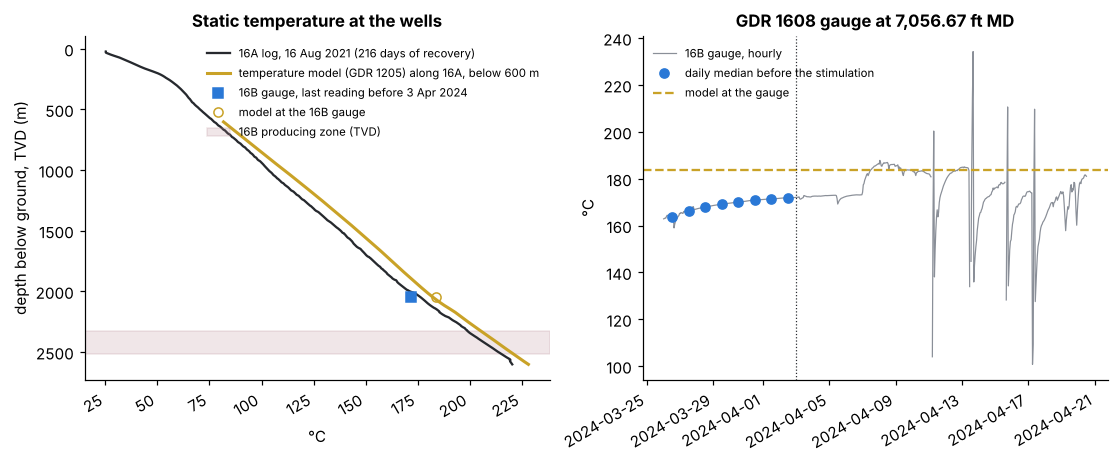

In [2]:
G = E["geotherm"]
m = np.load("data/forge_model.npz"); tr = json.loads(str(m["transform"])); Tn = m["T_c"].astype(float)
traj = pd.read_csv("data/trajectories_16A_16B.csv")
log = pd.read_csv("data/temperature_16A_2021.csv")
tA = traj[traj.well == "16A(78)-32"]
E_, N_, Z_ = (np.interp(log.md_m, tA.md_m, tA[c]) for c in ("easting", "northing", "elev_m"))
model_16A = ft.node_interp(Tn, tr, E_, N_, Z_)
deep = log.md_m > 600
bias = float(np.mean(model_16A[deep] - log.T_c[deep])); rmse = float(np.sqrt(np.mean((model_16A[deep] - log.T_c[deep]) ** 2)))
assert abs(bias - G["log_16A"]["bias_c"]) < 0.3 and abs(rmse - G["log_16A"]["rmse_c"]) < 0.3, (bias, rmse)
print(f"16A log (16 Aug 2021) against the model below 600 m: bias {bias:+.1f} °C, RMSE {rmse:.1f} °C (engine: {G['log_16A']['bias_c']:+.2f}, {G['log_16A']['rmse_c']:.2f})")
display(pd.DataFrame(G["log_16A"]["bins"]).round(1))
oi = G["log_16A"]["open_interval"]
print(f"16A open interval: log {oi['log_c']:.1f} °C, model {oi['model_c']:.1f} °C, model − log {oi['bias_c']:+.1f} °C")
pz = G["producing_zone_16B"]
print(f"16B producing zone ({pz['tvd_m'][0]:.0f}–{pz['tvd_m'][1]:.0f} m TVD): model {pz['model_c']:.1f} °C; the 16A log at the same depths {pz['log_16A_same_tvd_c']:.1f} °C; "
      f"model − log {pz['model_minus_log_c']:+.1f} °C")
g = pd.read_csv("data/pt_gauge_16B_2024_hourly.csv", parse_dates=["hour"])
q = g[(g.hour < "2024-04-03") & (g.T_c > 100)]
daily = q.groupby(q.hour.dt.date).T_c.median()
gs = G["gauge_16B"]
assert abs(daily.iloc[-1] - gs["last_c"]) < 0.2, (daily.iloc[-1], gs["last_c"])
print(f"16B gauge, {gs['tvd_m']:.0f} m TVD: {daily.iloc[0]:.1f} °C on {daily.index[0]} → {daily.iloc[-1]:.1f} °C on {daily.index[-1]}, "
      f"still warming {gs['warming_c_per_day_last3']:.2f} °C/day; recovery fit T∞ = {gs['recovery_fit']['T_inf_c']:.1f} °C")
print(f"model at the gauge {gs['model_c']:.1f} °C: {gs['model_minus_last_c']:+.1f} °C above the last reading, {gs['model_minus_fit_c']:+.1f} °C above the fit; "
      f"16A log at the same TVD {G['log_16A']['at_gauge_tvd']['log_c']:.1f} °C")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
tv = np.interp(log.md_m, tA.md_m, tA.elev_m.iloc[0] - tA.elev_m)
ax[0].plot(log.T_c, tv, color=CHARCOAL, lw=1.5, label="16A log, 16 Aug 2021 (216 days of recovery)")
ax[0].plot(np.where(deep, model_16A, np.nan), tv, color=GOLD, lw=2, label="temperature model (GDR 1205) along 16A, below 600 m")
ax[0].plot([gs["last_c"]], [gs["tvd_m"]], "s", color=BLUE, label="16B gauge, last reading before 3 Apr 2024")
ax[0].plot([gs["model_c"]], [gs["tvd_m"]], "o", mfc="none", color=GOLD, label="model at the 16B gauge")
ax[0].axhspan(*pz["tvd_m"], color=GRANITE, alpha=0.2, label="16B producing zone (TVD)")
ax[0].invert_yaxis(); ax[0].set_xlabel("°C"); ax[0].set_ylabel("depth below ground, TVD (m)"); ax[0].legend(fontsize=7.5); ax[0].set_title("Static temperature at the wells")
d = pd.Series([x["T_c"] for x in gs["daily"]], index=pd.to_datetime([x["date"] for x in gs["daily"]]))
ax[1].plot(g.hour, g.T_c.where(g.T_c > 100), color=GREY, lw=0.8, label="16B gauge, hourly")
ax[1].plot(d.index + pd.Timedelta(hours=12), d.values, "o", color=BLUE, label="daily median before the stimulation")
ax[1].axhline(gs["model_c"], color=GOLD, ls="--", label="model at the gauge")
ax[1].axvline(pd.Timestamp("2024-04-03"), color=CHARCOAL, lw=0.8, ls=":"); ax[1].set_ylabel("°C"); ax[1].legend(fontsize=7.5)
ax[1].set_title("GDR 1608 gauge at 7,056.67 ft MD"); fig.autofmt_xdate()
fig.savefig("figures/forge_geotherm_check.png")

**Reading it.** The temperature model is **hot at the wells**. Along 16A it is about 7 °C above a log that had recovered for 216 days; in the open interval the difference is about 6 °C. A log taken 216 days after drilling can still be a little cold, so part of this may be recovery. The 16B gauge agrees: in late March 2024 it read 172 °C and was still warming slowly, while the model gives 184 °C at that depth and the 16A log 176 °C. At the depths of the 16B producing zone, the model is about 8 °C above the 16A log. **So a hot temperature model is a real part of the +11 °C.** The model was built before 16A and 16B were drilled, so this is a blind check.

## 2 · Local thermal non-equilibrium: does it explain the last 11 °C?

The phase 4 model puts the water and the rock of a cell at one temperature. The tracers say the water crosses between the wells in hours, through a few paths. If those paths are sheets with large rock blocks between them, the water cannot take the rock's heat fast enough and arrives colder.

The engine now has a **dual-continuum heat option**: in each stimulated cell, the fracture water exchanges heat with nested shells of matrix by conduction (slab blocks of spacing D, MINC-like). It is checked against the parallel-fracture solution of Gringarten, Witherspoon and Ohnishi (1975) and its two limits (single fracture; local equilibrium). Each model below is recalibrated on the August injection pressure.

The block size D is the uncertain input. The data bound it: the 58-32 FMI log has a fracture every 0.27 m (all fractures; if all of them flowed, the blocks would be tiny), and the stimulated DFN of GDR 1646 has one plane every 38 m of cell (median; if only those planes flowed).

,block D (m),August T bottom hole (°C),misfit (°C),injector BHP (MPa),λ,T year 30 at 10 kg/s (°C),breakthrough (years)
0,LTE,214.50,11.61,42.03,0.15,117.85,0.51
1,1,214.43,11.55,42.03,0.15,119.48,0.44
2,2,214.13,11.24,42.04,0.15,119.40,0.43
3,4,212.57,9.68,42.05,0.15,119.06,0.39
4,8,206.75,3.86,42.07,0.16,118.31,0.26
5,16,195.57,-7.31,42.07,0.16,117.68,0.08
6,32,181.43,-21.45,42.11,0.17,117.48,0.02


median member: block size that brings the August bottom-hole temperature to the wellbore-implied 202.9 °C: D = 10.6 m (implied P10–P90 200.0–205.9 °C → D = 8.7–12.4 m)
after removing the hot geotherm at 16B (+8.2 °C): D = 5.3 m
with the tracer-implied transport porosity (× 30): D = 10.6 m
cube blocks (three fracture sets) at the same D: T bottom hole 212.3 °C; at 3 × D: 201.4 °C
data: FMI spacing 0.27 m (all fractures); stimulated DFN 1/P32 per cell 37.9 (22.0–151.5) m
ensemble (8 phase 4 members, D sampled log-uniform 0.27–38 m):
  misfit LTE +10.9 (+9.8–+13.1) °C; LTNE at the sampled D +10.2 (+4.2–+13.2) °C
  block size needed: 29.1 (20.9–41.1) m; after the geotherm correction 13.1 (10.3–19.8) m
  at the block size needed, 10 kg/s: T year 30 130.4 (124.3–138.1) °C (change +0.1 (-2.6–+1.4) °C); breakthrough 0.23 (0.17–0.28) years (change -86% (-91%–-80%))


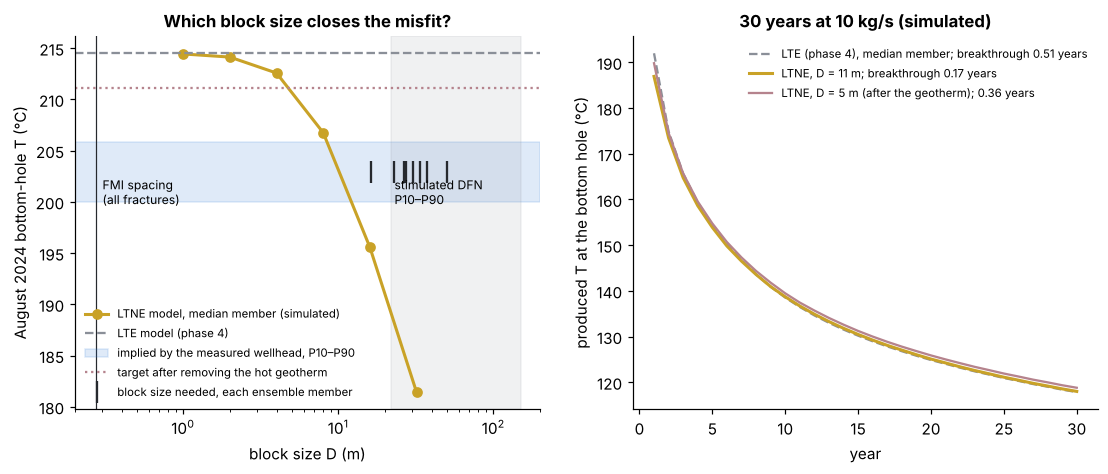

In [3]:
L = E["ltne_median"]; S = E["spacing"]; Tg = E["ltne_targets_c"]; LE = E["ltne_ensemble"]
imp = E["wellbore_implied_T_bottom_c"]
scan = pd.DataFrame([{"block D (m)": "LTE" if r["block_m"] is None else f"{r['block_m']:g}", "August T bottom hole (°C)": r["T_bottomhole_c"], "misfit (°C)": r["T_misfit_c"],
                      "injector BHP (MPa)": r["injector_bhp_mpa"], "λ": r["stim_aperture_factor"],
                      "T year 30 at 10 kg/s (°C)": r["forecast"]["T_prod_end_c"], "breakthrough (years)": r["forecast"]["breakthrough_years"]}
                     for r in [L["lte"]] + L["scan"]])
display(scan.round(2))
nd = L["needed"]
print(f"median member: block size that brings the August bottom-hole temperature to the wellbore-implied {imp['P50']:.1f} °C: D = {nd['P50']['block_m']:.1f} m "
      f"(implied P10–P90 {imp['P10']:.1f}–{imp['P90']:.1f} °C → D = {nd['P90']['block_m']:.1f}–{nd['P10']['block_m']:.1f} m)")
print(f"after removing the hot geotherm at 16B ({E['geotherm']['producing_zone_16B']['model_minus_log_c']:+.1f} °C): D = {nd['P50_geotherm_corrected']['block_m']:.1f} m")
print(f"with the tracer-implied transport porosity (× 30): D = {nd['P50_transport_porosity_x30']['block_m']:.1f} m")
v = L["variants"]
print(f"cube blocks (three fracture sets) at the same D: T bottom hole {v['cube_same_D']['T_bottomhole_c']:.1f} °C; at 3 × D: {v['cube_3D']['T_bottomhole_c']:.1f} °C")
print(f"data: FMI spacing {S['fmi_mean_spacing_m']:.2f} m (all fractures); stimulated DFN 1/P32 per cell {pct(S['dfn_cell_spacing_m'])} m")
print(f"ensemble ({LE['members'] - LE['failed']} phase 4 members, D sampled log-uniform {S['fmi_mean_spacing_m']:.2f}–{S['dfn_cell_spacing_m']['P50']:.0f} m):")
print(f"  misfit LTE {pct(LE['lte']['T_misfit_c'], '{:+.1f}')} °C; LTNE at the sampled D {pct(LE['ltne_sampled']['T_misfit_c'], '{:+.1f}')} °C")
print(f"  block size needed: {pct(LE['block_needed_m']['P50'])} m; after the geotherm correction {pct(LE['block_needed_m']['P50_geotherm_corrected'])} m")
A = LE["at_block_needed_P50"]
print(f"  at the block size needed, 10 kg/s: T year 30 {pct(A['T30_c'])} °C (change {pct(A['T30_change_c'], '{:+.1f}')} °C); "
      f"breakthrough {pct(A['breakthrough_years'], '{:.2f}')} years (change {pct(A['breakthrough_change'], '{:+.0%}')})")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
Ds = [r["block_m"] for r in L["scan"]]; Tb = [r["T_bottomhole_c"] for r in L["scan"]]
ax[0].plot(Ds, Tb, "o-", color=GOLD, lw=2, label="LTNE model, median member (simulated)")
ax[0].axhline(L["lte"]["T_bottomhole_c"], color=GREY, ls="--", label="LTE model (phase 4)")
ax[0].axhspan(imp["P10"], imp["P90"], color=BLUE, alpha=0.15, label="implied by the measured wellhead, P10–P90")
ax[0].axhline(Tg["P50_geotherm_corrected"], color=GRANITE, ls=":", label="target after removing the hot geotherm")
tx = ax[0].get_xaxis_transform()
ax[0].axvline(S["fmi_mean_spacing_m"], color=CHARCOAL, lw=0.8); ax[0].text(S["fmi_mean_spacing_m"] * 1.1, 0.55, "FMI spacing\n(all fractures)", fontsize=8, transform=tx)
ax[0].axvspan(S["dfn_cell_spacing_m"]["P10"], S["dfn_cell_spacing_m"]["P90"], color=GREY, alpha=0.12)
ax[0].text(S["dfn_cell_spacing_m"]["P10"] * 1.05, 0.55, "stimulated DFN\nP10–P90", fontsize=8, transform=tx)
ax[0].set_xscale("log"); ax[0].set_xlim(0.2, 200); ax[0].set_xlabel("block size D (m)"); ax[0].set_ylabel("August 2024 bottom-hole T (°C)"); ax[0].legend(fontsize=7.5, loc="lower left")
dn = [m_["needed"]["P50"]["block_m"] for m_ in E["ltne_members"] if m_["ok"] and m_["needed"]["P50"]["block_m"]]
ax[0].plot(dn, np.full(len(dn), imp["P50"]), "|", color=CHARCOAL, ms=14, mew=1.5, label="block size needed, each ensemble member")
ax[0].legend(fontsize=7.5, loc="lower left")
ax[0].set_title("Which block size closes the misfit?")
y = E["ltne_median"]["at_needed"]["slab"]["forecast"]["T_prod_yearly_c"]; y0 = L["lte"]["forecast"]["T_prod_yearly_c"]
bt = lambda r: r["forecast"]["breakthrough_years"]
ax[1].plot(range(1, len(y0) + 1), y0, color=GREY, ls="--", label=f"LTE (phase 4), median member; breakthrough {bt(L['lte']):.2f} years")
ax[1].plot(range(1, len(y) + 1), y, color=GOLD, lw=2, label=f"LTNE, D = {nd['P50']['block_m']:.0f} m; breakthrough {bt(L['at_needed']['slab']):.2f} years")
yc = E["ltne_median"]["at_needed"]["slab_geotherm_corrected"]["forecast"]["T_prod_yearly_c"]
ax[1].plot(range(1, len(yc) + 1), yc, color=GRANITE, lw=1.5, label=f"LTNE, D = {nd['P50_geotherm_corrected']['block_m']:.0f} m (after the geotherm); {bt(L['at_needed']['slab_geotherm_corrected']):.2f} years")
ax[1].set_xlabel("year"); ax[1].set_ylabel("produced T at the bottom hole (°C)"); ax[1].legend(fontsize=7.5); ax[1].set_title("30 years at 10 kg/s (simulated)")
fig.savefig("figures/forge_ltne.png")

**Reading it.** LTNE *can* close the misfit, but only with large blocks. For the ensemble, closing all of the +11 °C needs flowing sheets about **29 m apart (P10–P90 21–41 m)**; the median member needs 11 m. Then only the stimulated planes would carry water and the many small fractures of the FMI log would not. That is at the edge of the data: the stimulated DFN has a plane every 22–151 m of cell. Blocks drawn at random from the data range (0.27–38 m) mostly change nothing, because small blocks heat up in hours: LTNE then explains between 0 and 6 °C (P10–P90).

Once the hot temperature model is taken out (+8 °C at the 16B producing zone), LTNE has only about 3 °C left to explain. That needs blocks of **13 m (10–20 m)**, well inside the data range. Over 30 years the blocks heat through, so the 30-year temperature hardly changes (+0.1 °C, P10–P90 −2.6 to +1.4). But the 5 % breakthrough moves into the first months (0.23 years, P10–P90 0.17–0.28, against 1.8 years without LTNE), because the misfit LTNE explains is itself an early drop of that size.

**Our reading: most of the +11 °C is a hot temperature model (about 8 °C); the rest fits LTNE in blocks of 10–20 m.** Neither is forced by the data. A static temperature log in 16B, or temperature data from the first weeks of circulation, would separate the two.

## 3 · A local Shmin from the 16B mini-frac tests

Each test isolated a short open-hole interval of 16B between packers and pumped water in short cycles. When pumping stops, the pressure drops fast and then slowly. The pressure at the moment of shut-in (ISIP), taken from a straight line in √Δt, is an upper bound of the fracture closure pressure, which is the usual estimate of Shmin. We recompute the ISIPs from the data.

,test,md_ft,tvd_ft_kb,p_initial_psi,cycle,shut_in_s,isip_psi,max_psi,volume_l,gradient_psi_ft_ground
0,1,5657.319,5655.20,2431.68,1,2680.25,4527.61,4539.40,5.896,0.805
1,1,5657.319,5655.20,2431.68,2,4769.50,4383.56,4402.78,4.288,0.780
2,2,5494.279,5494.00,2358.23,1,2630.50,3362.39,3531.19,2.680,0.616
3,2,5494.279,5494.00,2358.23,2,6705.75,3277.27,3356.15,5.360,0.600
4,2,5494.279,5494.00,2358.23,3,12767.75,3338.07,3330.76,7.504,0.611
5,3,5201.859,5201.10,2228.84,1,1879.25,2743.56,2751.56,2.412,0.531
6,3,5201.859,5201.10,2228.84,2,4179.50,2899.84,2927.08,8.850,0.561
7,3,5201.859,5201.10,2228.84,3,8010.75,2880.85,2890.28,13.755,0.557
8,3,5201.859,5201.10,2228.84,4,12101.50,2876.87,2874.16,14.883,0.557
9,4,5980.238,5966.18,2545.76,1,1440.50,3360.68,3645.16,24.188,0.566


MF-2 ISIPs 3362, 3277, 3338 psi (report: 3288, 3237, 3323); gradient 0.611 psi/ft = 13.8 kPa/m below ground


,Shmin case,kPa/m,Shmin at 16A top completion (MPa)
0,gdr1222 recommended,17.00,40.35
1,minifrac isip mf2,13.82,32.81
2,report cooling mid,18.10,42.95
3,report cooling high,21.26,50.47


,Shmin case,Shmin (MPa),highest feasible rate (kg/s),members ≤ Shmin at 2.5 kg/s,members ≤ Shmin at 5 kg/s,members ≤ Shmin at 7.5 kg/s,members ≤ Shmin at 10 kg/s,members ≤ Shmin at 15 kg/s,members ≤ Shmin at 20 kg/s
0,gdr1222 recommended,40.3,9.5 (9.3–10.1),10/10,10/10,10/10,2/10,0/10,0/10
1,minifrac isip mf2,32.8,5.8 (5.3–6.3),10/10,9/10,0/10,0/10,0/10,0/10
2,report cooling mid,42.9,11.5 (10.9–11.8),10/10,10/10,10/10,10/10,0/10,0/10
3,report cooling high,50.5,17.2 (16.0–20.0),10/10,10/10,10/10,10/10,10/10,3/10


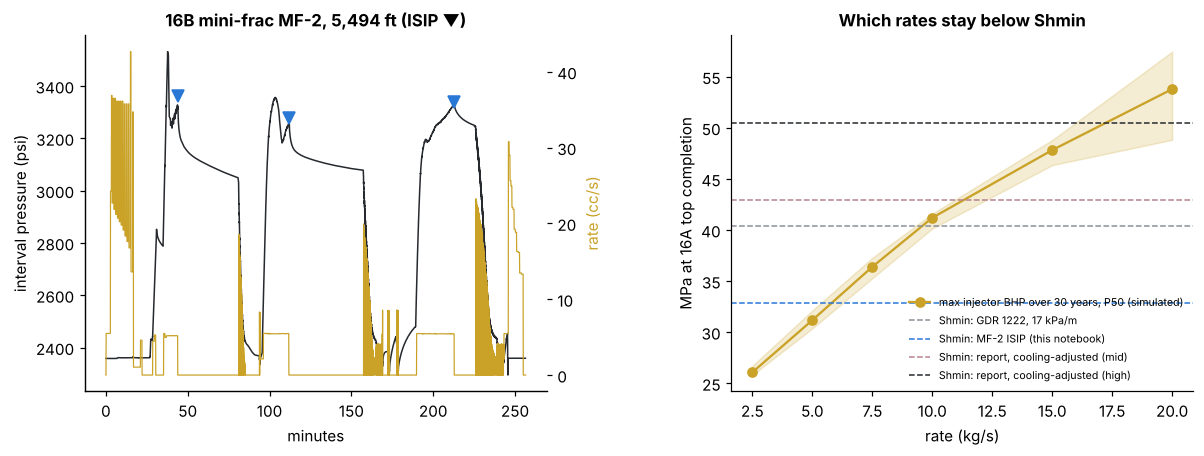

In [4]:
isip = pd.read_csv("data/minifrac_16B_2023_isip.csv")
isip["gradient_psi_ft_ground"] = isip.isip_psi / (isip.tvd_ft_kb - ft.KB_16B_FT)
display(isip.round(3))
M = E["minifrac"]["local_shmin"]
g2 = float(isip[isip.test == 2].gradient_psi_ft_ground.median())
assert abs(g2 - M["mf2_gradient_psi_ft_ground"]) < 1e-6, (g2, M["mf2_gradient_psi_ft_ground"])
mf2_isip = isip[isip.test == 2].isip_psi.values
assert np.allclose(mf2_isip, M["mf2_report_isip_psi"], rtol=0.03)
print(f"MF-2 ISIPs {', '.join(f'{v:.0f}' for v in mf2_isip)} psi (report: {', '.join(f'{v:.0f}' for v in M['mf2_report_isip_psi'])}); "
      f"gradient {g2:.3f} psi/ft = {g2 * ft.PSI_FT_TO_KPA_M:.1f} kPa/m below ground")
rows = [{"Shmin case": k.replace("_", " "), "kPa/m": v / 1e3, "Shmin at 16A top completion (MPa)": M["shmin_mpa"][k]} for k, v in M["gradients_pa_m"].items()]
display(pd.DataFrame(rows).round(2))
F = E["feasibility"]
rows = []
for k, c in F["cases"].items():
    rows.append({"Shmin case": k.replace("_", " "), "Shmin (MPa)": round(c["shmin_mpa"], 1), "highest feasible rate (kg/s)": pct(c["max_feasible_rate_kg_s"]),
                 **{f"members ≤ Shmin at {q} kg/s": f"{n}/{F['members'] - F['failed']}" for q, n in c["feasible_members_by_rate"].items()}})
display(pd.DataFrame(rows))
mf = pd.read_csv("data/minifrac_16B_2023_mf2.csv")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2)); fig.subplots_adjust(wspace=0.4)
ax[0].plot(mf.time_s / 60, mf.p_psi, color=CHARCOAL, lw=1)
a2 = ax[0].twinx(); a2.plot(mf.time_s / 60, mf.rate_cc_s, color=GOLD, lw=0.8); a2.set_ylabel("rate (cc/s)", color=GOLD)
for _, r in isip[isip.test == 2].iterrows():
    ax[0].plot(r.shut_in_s / 60, r.isip_psi, "v", color=BLUE, ms=8)
ax[0].set_xlabel("minutes"); ax[0].set_ylabel("interval pressure (psi)"); ax[0].set_title("16B mini-frac MF-2, 5,494 ft (ISIP ▼)")
qs = sorted(F["injector_bhp_max_mpa"], key=float)
ax[1].plot([float(q) for q in qs], [F["injector_bhp_max_mpa"][q]["P50"] for q in qs], "o-", color=GOLD, label="max injector BHP over 30 years, P50 (simulated)")
ax[1].fill_between([float(q) for q in qs], [F["injector_bhp_max_mpa"][q]["P10"] for q in qs], [F["injector_bhp_max_mpa"][q]["P90"] for q in qs], color=GOLD, alpha=0.2)
for (k, c), col in zip(F["cases"].items(), (GREY, BLUE, GRANITE, CHARCOAL)):
    lab = {"gdr1222_recommended": "GDR 1222, 17 kPa/m", "minifrac_isip_mf2": "MF-2 ISIP (this notebook)", "report_cooling_mid": "report, cooling-adjusted (mid)",
           "report_cooling_high": "report, cooling-adjusted (high)"}[k]
    ax[1].axhline(c["shmin_mpa"], color=col, ls="--", lw=1, label=f"Shmin: {lab}")
ax[1].set_xlabel("rate (kg/s)"); ax[1].set_ylabel("MPa at 16A top completion"); ax[1].legend(fontsize=7, loc="lower right"); ax[1].set_title("Which rates stay below Shmin")
fig.savefig("figures/forge_minifrac_shmin.png")

**Reading it.** The MF-2 ISIPs give 0.61 psi/ft (13.8 kPa/m). That is the low end of the GDR 1222 range (13.8 kPa/m), not its recommended 17 kPa/m. Carried down to 16A's top completion it is about **33 MPa**, against 40 MPa so far. Against it the highest rate that keeps 16A below Shmin for 30 years falls from about 9.5 kg/s to **5.8 kg/s** (P10–P90 5.3–6.3). The August 2024 test ran at 42.9 MPa, about 10 MPa above this value. The report adds a cooling correction (the hole was cooled before the tests) of +0.2 to +0.34 psi/ft. That would put Shmin at 43–50 MPa and the highest feasible rate at 11–17 kg/s. We cannot derive that correction from the files, so we show all four cases. Two limits: the tests are 550–800 m shallower than 16A's completion, and an ISIP is an upper bound of the closure pressure.

## 4 · A front correction for coarse models

Notebook 4 showed that KAI flow upscaling fixes the 30-year heat on 70 m cells, but not the early breakthrough. The correction tested here takes the breakthrough from **streamlines**: particles are traced (Pollock's method) on the fine-scale flux field that the KAI upscaling solves anyway. Each streamline carries its share of the rate; its cooling front travels with the local thermal retardation. No heat run is needed. The 30-year heat stays the coarse KAI model's.

**Pass criterion, stated before the run:** at 10 and 40 kg/s, the median breakthrough error against the 23.3 m model within ±15 %, its P10 and P90 within ±30 %, and the coarse KAI T year 30 still in its phase 4 class (median +2.4 ± 1 °C, P10–P90 inside −1 to +6 °C).

,rate (kg/s),model,"breakthrough error, P50 (P10–P90)"
0,10,"70 m, usual (Oda, Peaceman, recalibrated)",+25% (-32%–+62%)
1,10,"70 m, KAI upscaling (heat run)",+54% (-26%–+115%)
2,10,streamlines on the 70 m KAI flux (diagnostic),not defined: the 70 m well cells touch
3,10,streamlines on the fine flux (the correction),-48% (-59%–-43%)
4,10,"streamlines + conduction (diagnostic, defined ...",-35% (-46%–-30%)
5,10,fine 23.3 m: breakthrough (years),1.67 (1.28–1.85)
6,40,"70 m, usual (Oda, Peaceman, recalibrated)",+39% (-26%–+84%)
7,40,"70 m, KAI upscaling (heat run)",+72% (-16%–+141%)
8,40,streamlines on the 70 m KAI flux (diagnostic),not defined: the 70 m well cells touch
9,40,streamlines on the fine flux (the correction),-40% (-53%–-33%)


10 kg/s: checks {'median': False, 'p10_p90': False, 'T30': True}; coarse KAI T30 change +2.4 (-0.0–+5.1) °C
40 kg/s: checks {'median': False, 'p10_p90': False, 'T30': False}; coarse KAI T30 change -3.6 (-4.6–-1.3) °C
VERDICT: FAIL


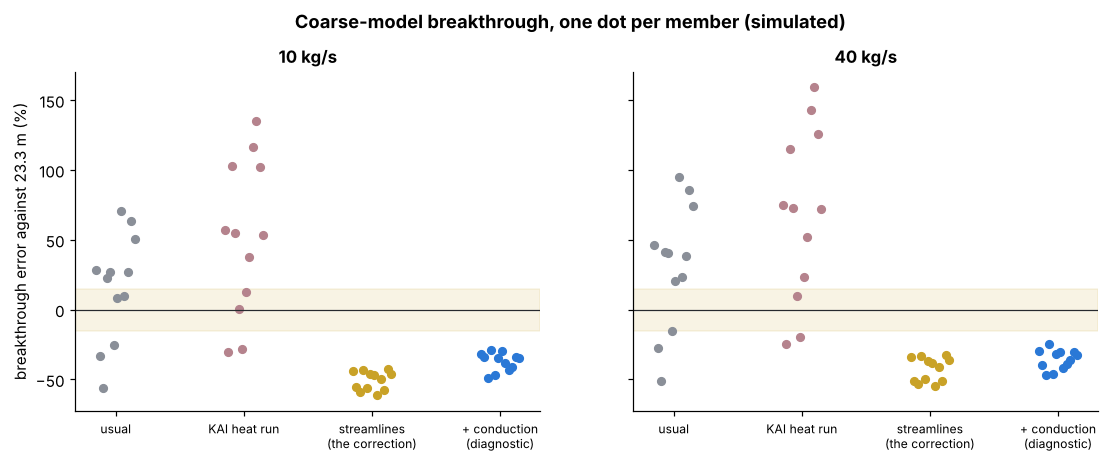

In [5]:
FC = E["front_correction"]
rows = []
for q, d in FC["rates"].items():
    for k, lab in (("coarse_usual", "70 m, usual (Oda, Peaceman, recalibrated)"), ("coarse_kai", "70 m, KAI upscaling (heat run)"),
                   ("tof_coarse_kai_flux", "streamlines on the 70 m KAI flux (diagnostic)"), ("tof_fine_flux", "streamlines on the fine flux (the correction)"),
                   ("tof_fine_flux_conduction", "streamlines + conduction (diagnostic, defined after a 2-member pilot)")):
        e = d[k]["breakthrough_change"]
        rows.append({"rate (kg/s)": q, "model": lab, "breakthrough error, P50 (P10–P90)": "not defined: the 70 m well cells touch" if e["P50"] is None else pct(e, "{:+.0%}")})
    rows.append({"rate (kg/s)": q, "model": "fine 23.3 m: breakthrough (years)", "breakthrough error, P50 (P10–P90)": pct(d["fine"]["breakthrough_years"], "{:.2f}")})
display(pd.DataFrame(rows))
for q, d in FC["rates"].items():
    print(f"{q} kg/s: checks {d['checks']}; coarse KAI T30 change {pct(d['coarse_kai']['T30_change_c'], '{:+.1f}')} °C")
print("VERDICT:", "PASS" if FC["pass"] else "FAIL")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.0), sharey=True)
mem = E["front_members"]
for a_, q in zip(ax, FC["rates"]):
    for i, (k, col, lab) in enumerate((("coarse_usual", GREY, "usual"), ("coarse_kai", GRANITE, "KAI heat run"),
                                       ("tof_fine_flux", GOLD, "streamlines, fine flux"), ("tof_fine_flux_conduction", BLUE, "+ conduction"))):
        e = [m["rates"][q][k]["breakthrough_change"] for m in mem if m["ok"] and m["rates"][q][k]["breakthrough_change"] is not None]
        a_.plot(np.full(len(e), i) + np.linspace(-0.15, 0.15, len(e)), np.array(e) * 100, "o", color=col, ms=5)
    a_.axhspan(-15, 15, color=GOLD, alpha=0.12); a_.axhline(0, color=CHARCOAL, lw=0.8)
    a_.set_xticks(range(4)); a_.set_xticklabels(["usual", "KAI heat run", "streamlines\n(the correction)", "+ conduction\n(diagnostic)"], fontsize=8); a_.set_title(f"{q} kg/s")
ax[0].set_ylabel("breakthrough error against 23.3 m (%)")
fig.suptitle("Coarse-model breakthrough, one dot per member (simulated)", y=1.02, fontweight="bold")
fig.savefig("figures/forge_front_correction.png")

**Is the fine model the right yardstick?** Notebook 4's grid study showed that the heat-run breakthrough still falls as the cells shrink. So the 23.3 m model is itself late. The table compares, for the median member, the heat runs of notebook 4 on three grids with the streamline breakthrough on the same grids.

In [6]:
FCV = E["front_convergence"]; ph4 = FCV["phase4"]
rows = [{"cells (m)": r["cell_m"], "heat run, notebook 4 (years)": h, "streamlines (years)": r["tof_years"], "streamlines + conduction (years)": r["tof_conduction_years"]}
        for r, h in zip(FCV["runs"], ph4["heat_run_breakthrough_years"])]
display(pd.DataFrame(rows).round(2))
print(f"heat runs, grid-converged: {ph4['converged_years']:.2f} ± {ph4['gci_years']:.2f} years")
tofs = [r["tof_years"] for r in FCV["runs"]]
print(f"streamlines change by {max(tofs) / min(tofs) - 1:.0%} from 52.5 to 23.3 m; heat runs by {ph4['heat_run_breakthrough_years'][0] / ph4['heat_run_breakthrough_years'][-1] - 1:.0%}")

,cells (m),"heat run, notebook 4 (years)",streamlines (years),streamlines + conduction (years)
0,52.50,2.67,0.87,0.90
1,35.00,1.65,0.86,1.05
2,23.33,1.37,0.79,1.02


heat runs, grid-converged: 1.26 ± 0.13 years
streamlines change by 11% from 52.5 to 23.3 m; heat runs by 95%


**Reading it. The correction fails.** On the fine flux, the streamline breakthrough is about 48 % early at 10 kg/s and 40 % early at 40 kg/s, with every member outside ±30 %. Adding heat conducted in from the rock beside each streamline (a diagnostic, defined after a two-member pilot) still leaves it about 35 % early. On the 70 m flux, streamlines are not even defined: the injector and producer cells touch, because the open intervals are only 90–108 m apart. That is also why no 70 m model can resolve this front.

The yardstick is part of the story. The streamline answer hardly moves with the cell size, while the heat runs halve from 52.5 to 23.3 m and still have not converged. With conduction, the streamlines are 19 % below the converged heat run of the median member. A correction that passes would need the heat exchange between the flowing sheets and the rock beside them, and a converged reference. **Until then, the case page shows only the 30-year heat result for coarse models.**

## Published numbers

In [7]:
now = {"geo_16A_bias_c": G["log_16A"]["bias_c"], "geo_16A_rmse_c": G["log_16A"]["rmse_c"], "geo_16A_open_bias_c": G["log_16A"]["open_interval"]["bias_c"],
       "geo_16B_pz_model_minus_log_c": G["producing_zone_16B"]["model_minus_log_c"], "geo_gauge_last_c": G["gauge_16B"]["last_c"],
       "geo_gauge_model_c": G["gauge_16B"]["model_c"],
       "ltne_D_needed_P50_median_member_m": L["needed"]["P50"]["block_m"], "ltne_D_needed_geo_median_member_m": L["needed"]["P50_geotherm_corrected"]["block_m"],
       "ltne_T30_needed_median_member_c": L["at_needed"]["slab"]["forecast"]["T_prod_end_c"], "ltne_bt_needed_median_member_y": L["at_needed"]["slab"]["forecast"]["breakthrough_years"],
       "ltne_T30_lte_median_member_c": L["lte"]["forecast"]["T_prod_end_c"], "ltne_bt_lte_median_member_y": L["lte"]["forecast"]["breakthrough_years"],
       "mf2_gradient_psi_ft": M["mf2_gradient_psi_ft_ground"], "shmin_mf2_mpa": M["shmin_mpa"]["minifrac_isip_mf2"], "front_pass": FC["pass"],
       "front_conv_tof_23m_y": FCV["runs"][-1]["tof_years"], "front_conv_tofc_23m_y": FCV["runs"][-1]["tof_conduction_years"]}
for lvl in ("P10", "P50", "P90"):
    now[f"ltne_D_needed_ens_{lvl}"] = LE["block_needed_m"]["P50"][lvl]
    now[f"ltne_D_needed_geo_ens_{lvl}"] = LE["block_needed_m"]["P50_geotherm_corrected"][lvl]
    now[f"ltne_misfit_sampled_{lvl}"] = LE["ltne_sampled"]["T_misfit_c"][lvl]
    now[f"ltne_T30_change_{lvl}"] = LE["at_block_needed_P50"]["T30_change_c"][lvl]
    now[f"ltne_bt_change_{lvl}"] = LE["at_block_needed_P50"]["breakthrough_change"][lvl]
    for k, c in F["cases"].items():
        now[f"maxrate_{k}_{lvl}"] = c["max_feasible_rate_kg_s"][lvl]
    for q, d in FC["rates"].items():
        now[f"front_tof_{q}_{lvl}"] = d["tof_fine_flux"]["breakthrough_change"][lvl]
        now[f"front_kai_{q}_{lvl}"] = d["coarse_kai"]["breakthrough_change"][lvl]
if {'geo_16A_bias_c': 6.984532078417527, 'geo_16A_rmse_c': 7.111220120825339, 'geo_16A_open_bias_c': 5.906783794364893, 'geo_16B_pz_model_minus_log_c': 8.241582973407496, 'geo_gauge_last_c': 171.93, 'geo_gauge_model_c': 183.63552229655014, 'ltne_D_needed_P50_median_member_m': 10.62115739498255, 'ltne_D_needed_geo_median_member_m': 5.268020436459234, 'ltne_T30_needed_median_member_c': 117.99530603905858, 'ltne_bt_needed_median_member_y': 0.1731721966278235, 'ltne_T30_lte_median_member_c': 117.8454449384707, 'ltne_bt_lte_median_member_y': 0.5126241452305929, 'mf2_gradient_psi_ft': 0.6111447489746672, 'shmin_mf2_mpa': 32.810382343374194, 'front_pass': False, 'front_conv_tof_23m_y': 0.7886459245914087, 'front_conv_tofc_23m_y': 1.0173501064699197, 'ltne_D_needed_ens_P10': 20.929708222850167, 'ltne_D_needed_geo_ens_P10': 10.25309855552459, 'ltne_misfit_sampled_P10': 4.218318073127756, 'ltne_T30_change_P10': -2.6298599621886183, 'ltne_bt_change_P10': -0.9148971909825808, 'maxrate_gdr1222_recommended_P10': 9.274212121537337, 'maxrate_minifrac_isip_mf2_P10': 5.340578329983259, 'maxrate_report_cooling_mid_P10': 10.89059326713699, 'maxrate_report_cooling_high_P10': 15.977736063950323, 'front_tof_10_P10': -0.5889268351050493, 'front_kai_10_P10': -0.25596534214453714, 'front_tof_40_P10': -0.5286728232534231, 'front_kai_40_P10': -0.16486737273423846, 'ltne_D_needed_ens_P50': 29.060120121415956, 'ltne_D_needed_geo_ens_P50': 13.051245909545178, 'ltne_misfit_sampled_P50': 10.196548850812604, 'ltne_T30_change_P50': 0.14939166745752175, 'ltne_bt_change_P50': -0.8623365361578965, 'maxrate_gdr1222_recommended_P50': 9.53490261179349, 'maxrate_minifrac_isip_mf2_P50': 5.786683178059798, 'maxrate_report_cooling_mid_P50': 11.45035788308677, 'maxrate_report_cooling_high_P50': 17.240285901578616, 'front_tof_10_P50': -0.4815159467389071, 'front_kai_10_P50': 0.5395396276909319, 'front_tof_40_P50': -0.39567076594244266, 'front_kai_40_P50': 0.7242740813217983, 'ltne_D_needed_ens_P90': 41.12952172569376, 'ltne_D_needed_geo_ens_P90': 19.78856029827079, 'ltne_misfit_sampled_P90': 13.160172751284346, 'ltne_T30_change_P90': 1.4030351498662725, 'ltne_bt_change_P90': -0.8007347614067604, 'maxrate_gdr1222_recommended_P90': 10.133476305016375, 'maxrate_minifrac_isip_mf2_P90': 6.250312365168773, 'maxrate_report_cooling_mid_P90': 11.78311866940283, 'maxrate_report_cooling_high_P90': 20.0, 'front_tof_10_P90': -0.4327879643435137, 'front_kai_10_P90': 1.152485890986813, 'front_tof_40_P90': -0.33198944471047975, 'front_kai_40_P90': 1.414980244087259} is None:
    pathlib.Path("results/nb6_phase5_checks.json").write_text(json.dumps({"published": now}, indent=1)); print("first pass: numbers written, not checked")
else:
    published = {'geo_16A_bias_c': 6.984532078417527, 'geo_16A_rmse_c': 7.111220120825339, 'geo_16A_open_bias_c': 5.906783794364893, 'geo_16B_pz_model_minus_log_c': 8.241582973407496, 'geo_gauge_last_c': 171.93, 'geo_gauge_model_c': 183.63552229655014, 'ltne_D_needed_P50_median_member_m': 10.62115739498255, 'ltne_D_needed_geo_median_member_m': 5.268020436459234, 'ltne_T30_needed_median_member_c': 117.99530603905858, 'ltne_bt_needed_median_member_y': 0.1731721966278235, 'ltne_T30_lte_median_member_c': 117.8454449384707, 'ltne_bt_lte_median_member_y': 0.5126241452305929, 'mf2_gradient_psi_ft': 0.6111447489746672, 'shmin_mf2_mpa': 32.810382343374194, 'front_pass': False, 'front_conv_tof_23m_y': 0.7886459245914087, 'front_conv_tofc_23m_y': 1.0173501064699197, 'ltne_D_needed_ens_P10': 20.929708222850167, 'ltne_D_needed_geo_ens_P10': 10.25309855552459, 'ltne_misfit_sampled_P10': 4.218318073127756, 'ltne_T30_change_P10': -2.6298599621886183, 'ltne_bt_change_P10': -0.9148971909825808, 'maxrate_gdr1222_recommended_P10': 9.274212121537337, 'maxrate_minifrac_isip_mf2_P10': 5.340578329983259, 'maxrate_report_cooling_mid_P10': 10.89059326713699, 'maxrate_report_cooling_high_P10': 15.977736063950323, 'front_tof_10_P10': -0.5889268351050493, 'front_kai_10_P10': -0.25596534214453714, 'front_tof_40_P10': -0.5286728232534231, 'front_kai_40_P10': -0.16486737273423846, 'ltne_D_needed_ens_P50': 29.060120121415956, 'ltne_D_needed_geo_ens_P50': 13.051245909545178, 'ltne_misfit_sampled_P50': 10.196548850812604, 'ltne_T30_change_P50': 0.14939166745752175, 'ltne_bt_change_P50': -0.8623365361578965, 'maxrate_gdr1222_recommended_P50': 9.53490261179349, 'maxrate_minifrac_isip_mf2_P50': 5.786683178059798, 'maxrate_report_cooling_mid_P50': 11.45035788308677, 'maxrate_report_cooling_high_P50': 17.240285901578616, 'front_tof_10_P50': -0.4815159467389071, 'front_kai_10_P50': 0.5395396276909319, 'front_tof_40_P50': -0.39567076594244266, 'front_kai_40_P50': 0.7242740813217983, 'ltne_D_needed_ens_P90': 41.12952172569376, 'ltne_D_needed_geo_ens_P90': 19.78856029827079, 'ltne_misfit_sampled_P90': 13.160172751284346, 'ltne_T30_change_P90': 1.4030351498662725, 'ltne_bt_change_P90': -0.8007347614067604, 'maxrate_gdr1222_recommended_P90': 10.133476305016375, 'maxrate_minifrac_isip_mf2_P90': 6.250312365168773, 'maxrate_report_cooling_mid_P90': 11.78311866940283, 'maxrate_report_cooling_high_P90': 20.0, 'front_tof_10_P90': -0.4327879643435137, 'front_kai_10_P90': 1.152485890986813, 'front_tof_40_P90': -0.33198944471047975, 'front_kai_40_P90': 1.414980244087259}
    for k, v in published.items():
        x = now[k]
        if isinstance(v, str) or isinstance(x, str) or v is None or x is None:
            assert x == v, (k, x, v)
        else:
            assert abs(x - v) <= 0.02 * abs(v) + 0.01, (k, x, v)
    pathlib.Path("results/nb6_phase5_checks.json").write_text(json.dumps({"published": now}, indent=1))
    print(f"all {len(published)} published numbers reproduced")

all 56 published numbers reproduced


## What this says, and what it does not

The temperature model is hot at the wells: about +7 °C along a 16A log after 216 days of recovery and about +8 °C at the depths of the 16B producing zone. That explains most of the +11 °C bottom-hole misfit. Local thermal non-equilibrium in flowing sheets 10–20 m apart explains the rest; closing the whole misfit with it alone would need 21–41 m. LTNE leaves the 30-year temperature unchanged but brings the 5 % breakthrough into the first months. The 16B mini-frac ISIPs put Shmin at about 33 MPa at 16A, and the highest feasible rate at about 6 kg/s; the report's cooling correction would raise them to 43–50 MPa and 11–17 kg/s. The streamline front correction for coarse models failed its stated test, so coarse models still give only the 30-year heat. All model numbers are simulated.

**Limits.** LTNE uses one block size for all stimulated cells, slab blocks, and the phase 4 fracture porosity; the block size is fitted, not measured. The geotherm check rests on one 16A log (216 days of recovery, so possibly still slightly cold) and one 16B gauge that was still warming. The local Shmin comes from tests 550–800 m above 16A's completion; the cooling correction is the report's, not ours. The front correction uses the fine-scale flux field, which the KAI upscaling has anyway; it has no conduction or dispersion.

*References:* Gringarten, A. C., Witherspoon, P. A. and Ohnishi, Y. (1975). Theory of heat extraction from fractured hot dry rock. JGR 80(8) · Pruess, K. and Narasimhan, T. N. (1985). A practical method for modeling fluid and heat flow in fractured porous media. SPE Journal 25(1) · Pollock, D. W. (1988). Semianalytical computation of path lines for finite-difference models. Ground Water 26(6) · Abate, J. and Valkó, P. P. (2004). Multi-precision Laplace transform inversion. IJNME 60.